# SP-004 — Pair-Block v2

Adaptación limitada a parejas de Cai et al. (2023), DOI 10.1016/j.cor.2023.106398. v2 usa giros de 5° y deduplicación por máscara raster; no reproduce el método completo.

Configuración TA-027: raster 1 mm, giros 5°; SMALL margen/separación 0/0 mm y MEDIUM/COMPLEX 1/1 mm. Prioridad retazo → plancha.

## Entorno reproducible

In [1]:
# Importamos Path para resolver rutas en local y Colab.
from pathlib import Path
# Importamos sys para habilitar imports del backend.
import sys
# Leemos resultados sin depender de pandas.
import csv
# Leemos trazas crudas en JSON.
import json
# Liberamos memoria entre corridas secuenciales.
import gc
# Tomamos el directorio actual como raíz candidata.
repo_root = Path.cwd()
# Detectamos si Colab abrió desde otra carpeta.
if not (repo_root / "experiments/optimization/loader.py").exists():
    # Usamos la ruta habitual del clon en Colab.
    repo_root = Path("/content/NewGlass")
# Validamos que el repositorio esté disponible.
if not (repo_root / "experiments/optimization/loader.py").exists():
    # Damos una instrucción accionable.
    raise RuntimeError("Abre desde la raíz de NewGlass o clona en /content/NewGlass.")
# Habilitamos imports de la capa de dominio.
sys.path.insert(0, str(repo_root / "backend"))
# Habilitamos imports del laboratorio experimental.
sys.path.insert(0, str(repo_root))
# Importamos FF actual.
from app.modules.optimization.domain.first_fit import FirstFitOptimizer
# Importamos BF actual.
from app.modules.optimization.domain.best_fit import BestFitOptimizer
# Importamos WF actual.
from app.modules.optimization.domain.worst_fit import WorstFitOptimizer
# Importamos Pair-Block aislado.
from experiments.optimization.block_packing import BlockPackingExperimental
# Reutilizamos el ejecutor con métricas NewGlass.
from experiments.optimization.block_packing.run_benchmark import run_one
# Reutilizamos el loader y fixtures congelados.
from experiments.optimization.loader import CASES, load_problem, read_case
# Guardamos filas y placements para compararlos después.
benchmark_rows = {}
# Asociamos cada etiqueta con su clase.
optimizer_by_method = {"FF": FirstFitOptimizer, "BF": BestFitOptimizer, "WF": WorstFitOptimizer, "Pair-Block-v2": BlockPackingExperimental}
# Confirmamos qué copia del repo se usa.
print("Repositorio:", repo_root)
# Confirmamos orden y ausencia de paralelismo.
print("Ejecución: secuencial; casos oficiales:", CASES)

Repositorio: C:\Users\patri\GitHub\optimizador-vidrio
Ejecución: secuencial; casos oficiales: ('EXP-SMALL-001', 'EXP-MEDIUM-001', 'EXP-COMPLEX-001')


**Interpretación:** Pair-Block se importa desde experiments/; FF/BF/WF siguen siendo el código actual.

## Entradas y fixtures

Ejecuta el paso experimental y muestra su salida guardada.

In [2]:
# Recorremos los fixtures oficiales en el orden congelado.
for case_id in CASES:
    # Leemos el JSON sin modificarlo.
    case_data = read_case(case_id)
    # Creamos snapshots independientes para el motor.
    problem = load_problem(case_id)
    # Resumimos entrada y compatibilidades.
    print(case_id, "unidades:", len(problem.units), "grupos:", len(problem.groups), "fuentes:", len(case_data["stock"]))
# Cargamos aparte la demo no oficial.
block_data = json.loads((repo_root / "experiments/optimization/block_packing/cases/BLOCK-DISCRIMINANT-001.json").read_text(encoding="utf-8"))
# Separamos la demo de TA-027.
print(block_data["label"], "piezas:", sum(item["cantidad"] for item in block_data["pieces"]))
# Enumeramos los casos congelados.
for diagnostic_id in ("BLOCK-V2-OBLIQUE-TRIANGLES-001", "BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001"):
    # Leemos su propósito previo.
    diagnostic = json.loads((repo_root / "experiments/optimization/block_packing/cases" / f"{diagnostic_id}.json").read_text(encoding="utf-8"))
    # Mostramos propósito y tamaño.
    print(diagnostic_id, diagnostic["diagnostic_intent"], "piezas:", len(diagnostic["pieces"]))

EXP-SMALL-001 unidades: 3 grupos: 1 fuentes: 2
EXP-MEDIUM-001 unidades: 9 grupos: 1 fuentes: 3
EXP-COMPLEX-001 unidades: 24 grupos: 2 fuentes: 5
DEMO DIDÁCTICA — NO PERTENECE AL BENCHMARK OFICIAL piezas: 3
BLOCK-V2-OBLIQUE-TRIANGLES-001 Dos triángulos convexos son las mitades de un rectángulo 10x6 rotado 30 grados. Se observa si la grilla de 5 grados puede recuperar la composición oblicua; no se presupone mejora de métricas. piezas: 2
BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 Un círculo pequeño se ubica en la esquina vacía del bounding box de un triángulo rectángulo. Se observa complementariedad entre tipos geométricos distintos con separación de 1 mm; no se presupone mejora de métricas. piezas: 2


**Interpretación:** El caso adicional prueba composición y trazabilidad; sus métricas no se mezclan con los resultados TA-027.

## Criterio de aceptación del bloque

Ejecuta el paso experimental y muestra su salida guardada.

In [3]:
# Definimos la mejora del sobre conjunto.
def bbox_saving(area_a, area_b, area_union):
    # Comparamos cajas separadas frente a la caja del bloque.
    return area_a + area_b - area_union
# Mostramos un bloque complementario ideal.
print("ejemplo: dos huellas triangulares con cajas 10×10 dentro de caja conjunta 10×10:", bbox_saving(100, 100, 100), "celdas ahorradas")

ejemplo: dos huellas triangulares con cajas 10×10 dentro de caja conjunta 10×10: 100 celdas ahorradas


**Interpretación:** El criterio mide reducción de bounding box, no atribuye una fórmula al artículo; una mera vecindad con cajas separadas no obtiene ahorro positivo.

## Filtros y contadores de pruning

Ejecuta el paso experimental y muestra su salida guardada.

In [4]:
# Abrimos la traza serializada.
trace_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_block_v2_trace.json"
# Leemos los contadores medidos.
trace_data = json.loads(trace_path.read_text(encoding="utf-8"))
# Recorremos métodos y casos registrados.
for entry in trace_data["results"]:
    # Filtramos la política experimental.
    if entry["method"] == "Pair-Block-v2":
        # Tomamos el desglose de pruning.
        item = entry["block_trace"]
        # Mostramos contadores crudos.
        print(entry["case"], item["candidate_pairs"], item["compatible_pairs"], item["filtered_pairs"], item["orientation_combinations_theoretical"], item["orientation_combinations_pruned"], item["orientation_combinations_evaluated"], item["relative_positions_pruned"], item["relative_positions_checked"])

EXP-SMALL-001 3 3 0 15552 15543 9 210 81
EXP-MEDIUM-001 36 36 0 186624 185048 1576 81915 16579
EXP-COMPLEX-001 276 181 95 1430784 1420632 10152 544518 104218
BLOCK-DISCRIMINANT-001 3 3 0 15552 15336 216 10668 3060
BLOCK-V2-OBLIQUE-TRIANGLES-001 1 1 0 5184 5112 72 3546 1062
BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 1 1 0 5184 5164 20 2361 455


**Interpretación:** El total incluye pares incompatibles por material/espesor; estos se podan antes de orientar. La fase y los offsets también son heurísticos y sus cantidades se distinguen.

## Grilla angular y separación

Ejecuta el paso experimental y muestra su salida guardada.

In [5]:
# Leemos la configuración oficial.
small_config = read_case("EXP-SMALL-001")["config"]
# Recuperamos el paso común.
step = small_config["angular_step_deg"]
# Enumeramos únicamente ángulos de la grilla común.
allowed_angles = list(range(0, 360, step))
# Resumimos sin crear ángulos nuevos.
print("paso:", step, "grados; cantidad:", len(allowed_angles), "primeros:", allowed_angles[:5], "último:", allowed_angles[-1])

paso: 5 grados; cantidad: 72 primeros: [0, 5, 10, 15, 20] último: 355


**Interpretación:** La caché común rasteriza las orientaciones; la separación y colisión se validan con la misma operación de dilatación por celdas que el motor.

## Demo gráfica de dos triángulos

Ejecuta el paso experimental y muestra su salida guardada.

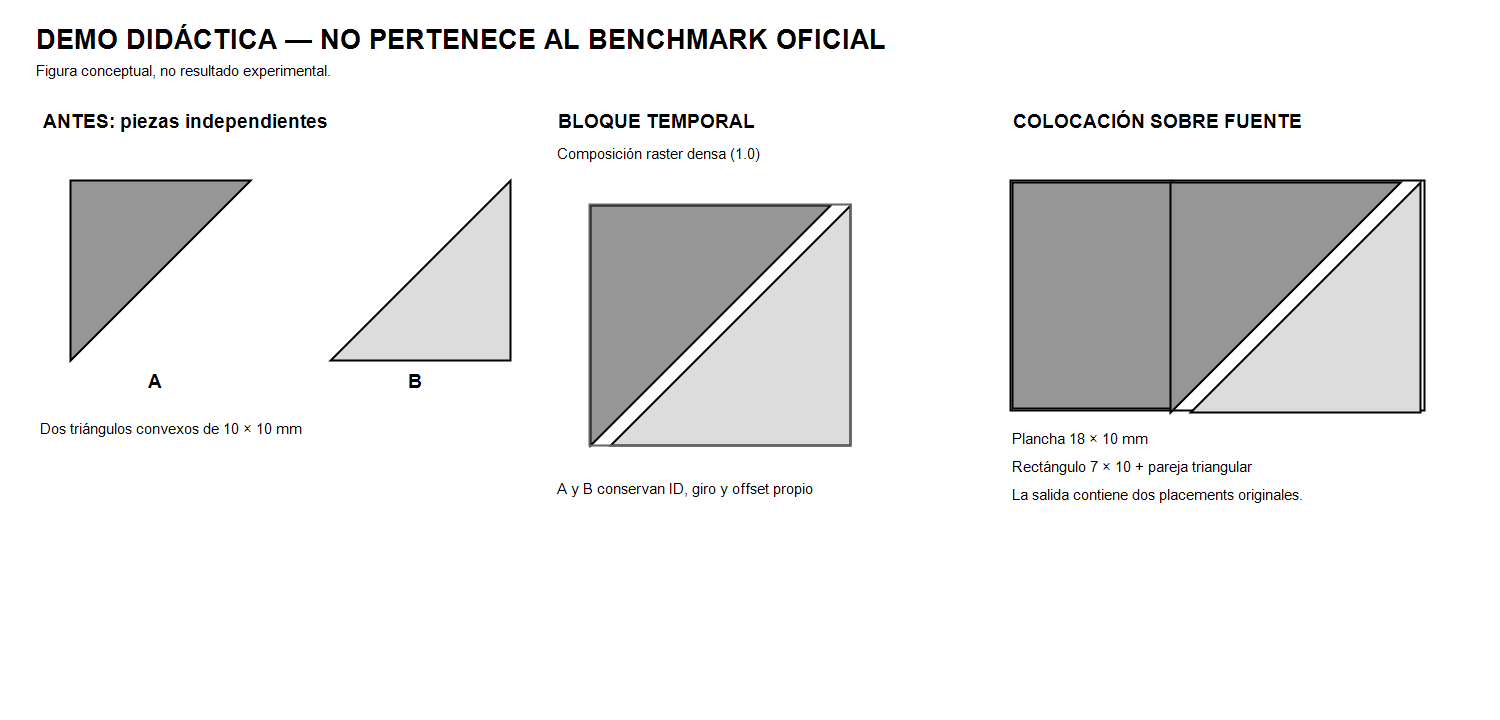

In [6]:
# Importamos el visor de imágenes de Jupyter/Colab.
from IPython.display import Image, display
# Localizamos la ilustración en grises.
demo_path = repo_root / "experiments/optimization/block_packing/figures/block-packing-demo.png"
# Mostramos los tres estados de la composición.
display(Image(filename=str(demo_path)))

**Interpretación:** La pareja demostrativa alcanza compactación raster 1.0 y conserva IDs, giros y offsets propios.

## EXP-SMALL-001 — FF

Ejecuta el paso experimental y muestra su salida guardada.

In [7]:
# Seleccionamos una instancia fija de la matriz.
case_id = "EXP-SMALL-001"
# Elegimos el método que corre en esta celda.
method_name = "FF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = FirstFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"EXP-SMALL-001 FF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

EXP-SMALL-001 FF: 3/3; uso=60.000%; merma=0.00 mm²; retazos=1; planchas=1; runtime=11.690 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## EXP-SMALL-001 — BF

Ejecuta el paso experimental y muestra su salida guardada.

In [8]:
# Seleccionamos una instancia fija de la matriz.
case_id = "EXP-SMALL-001"
# Elegimos el método que corre en esta celda.
method_name = "BF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = BestFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"EXP-SMALL-001 BF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

EXP-SMALL-001 BF: 3/3; uso=60.000%; merma=0.00 mm²; retazos=1; planchas=1; runtime=10.893 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## EXP-SMALL-001 — WF

Ejecuta el paso experimental y muestra su salida guardada.

In [9]:
# Seleccionamos una instancia fija de la matriz.
case_id = "EXP-SMALL-001"
# Elegimos el método que corre en esta celda.
method_name = "WF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = WorstFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"EXP-SMALL-001 WF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

EXP-SMALL-001 WF: 3/3; uso=60.000%; merma=0.00 mm²; retazos=1; planchas=1; runtime=10.899 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## EXP-SMALL-001 — Pair-Block-v2

Ejecuta el paso experimental y muestra su salida guardada.

In [10]:
# Seleccionamos una instancia fija de la matriz.
case_id = "EXP-SMALL-001"
# Elegimos el método que corre en esta celda.
method_name = "Pair-Block-v2"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = BlockPackingExperimental
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"EXP-SMALL-001 Pair-Block-v2: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")
# Separamos generación y packing.
print("bloques aceptados/colocados:", row["accepted_blocks"], row["placed_blocks"], "generación ms:", row["block_generation_ms"], "packing ms:", row["packing_ms"])

EXP-SMALL-001 Pair-Block-v2: 3/3; uso=60.000%; merma=0.00 mm²; retazos=1; planchas=1; runtime=12.031 ms
bloques aceptados/colocados: 0 0 generación ms: 10.229 packing ms: 0.921


**Interpretación:** Clasificación D: no se colocó ningún bloque y no aplica E. Pair-Block v2 colocó 3/3; runtime total 12.457 ms, generación 10.686 ms, packing 0.911 ms; ratio 1.161× frente al baseline más rápido.

## EXP-MEDIUM-001 — FF

Ejecuta el paso experimental y muestra su salida guardada.

In [11]:
# Seleccionamos una instancia fija de la matriz.
case_id = "EXP-MEDIUM-001"
# Elegimos el método que corre en esta celda.
method_name = "FF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = FirstFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"EXP-MEDIUM-001 FF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

EXP-MEDIUM-001 FF: 9/9; uso=28.413%; merma=201.86 mm²; retazos=2; planchas=1; runtime=18.599 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## EXP-MEDIUM-001 — BF

Ejecuta el paso experimental y muestra su salida guardada.

In [12]:
# Seleccionamos una instancia fija de la matriz.
case_id = "EXP-MEDIUM-001"
# Elegimos el método que corre en esta celda.
method_name = "BF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = BestFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"EXP-MEDIUM-001 BF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

EXP-MEDIUM-001 BF: 9/9; uso=28.413%; merma=193.86 mm²; retazos=2; planchas=1; runtime=28.528 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## EXP-MEDIUM-001 — WF

Ejecuta el paso experimental y muestra su salida guardada.

In [13]:
# Seleccionamos una instancia fija de la matriz.
case_id = "EXP-MEDIUM-001"
# Elegimos el método que corre en esta celda.
method_name = "WF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = WorstFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"EXP-MEDIUM-001 WF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

EXP-MEDIUM-001 WF: 9/9; uso=18.584%; merma=301.86 mm²; retazos=2; planchas=2; runtime=18.873 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## EXP-MEDIUM-001 — Pair-Block-v2

Ejecuta el paso experimental y muestra su salida guardada.

In [14]:
# Seleccionamos una instancia fija de la matriz.
case_id = "EXP-MEDIUM-001"
# Elegimos el método que corre en esta celda.
method_name = "Pair-Block-v2"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = BlockPackingExperimental
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"EXP-MEDIUM-001 Pair-Block-v2: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")
# Separamos generación y packing.
print("bloques aceptados/colocados:", row["accepted_blocks"], row["placed_blocks"], "generación ms:", row["block_generation_ms"], "packing ms:", row["packing_ms"])

EXP-MEDIUM-001 Pair-Block-v2: 9/9; uso=28.413%; merma=201.86 mm²; retazos=2; planchas=1; runtime=228.781 ms
bloques aceptados/colocados: 0 0 generación ms: 221.195 packing ms: 5.249


**Interpretación:** Clasificación E: empeora al menos una métrica funcional. Pair-Block v2 colocó 9/9; runtime total 231.137 ms, generación 224.766 ms, packing 3.999 ms; ratio 12.549× frente al baseline más rápido.

## EXP-COMPLEX-001 — FF

Ejecuta el paso experimental y muestra su salida guardada.

In [15]:
# Seleccionamos una instancia fija de la matriz.
case_id = "EXP-COMPLEX-001"
# Elegimos el método que corre en esta celda.
method_name = "FF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = FirstFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"EXP-COMPLEX-001 FF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

EXP-COMPLEX-001 FF: 24/24; uso=29.598%; merma=746.72 mm²; retazos=3; planchas=3; runtime=94.676 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## EXP-COMPLEX-001 — BF

Ejecuta el paso experimental y muestra su salida guardada.

In [16]:
# Seleccionamos una instancia fija de la matriz.
case_id = "EXP-COMPLEX-001"
# Elegimos el método que corre en esta celda.
method_name = "BF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = BestFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"EXP-COMPLEX-001 BF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

EXP-COMPLEX-001 BF: 24/24; uso=29.598%; merma=746.72 mm²; retazos=3; planchas=3; runtime=98.659 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## EXP-COMPLEX-001 — WF

Ejecuta el paso experimental y muestra su salida guardada.

In [17]:
# Seleccionamos una instancia fija de la matriz.
case_id = "EXP-COMPLEX-001"
# Elegimos el método que corre en esta celda.
method_name = "WF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = WorstFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"EXP-COMPLEX-001 WF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

EXP-COMPLEX-001 WF: 24/24; uso=25.309%; merma=886.72 mm²; retazos=3; planchas=4; runtime=102.014 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## EXP-COMPLEX-001 — Pair-Block-v2

Ejecuta el paso experimental y muestra su salida guardada.

In [18]:
# Seleccionamos una instancia fija de la matriz.
case_id = "EXP-COMPLEX-001"
# Elegimos el método que corre en esta celda.
method_name = "Pair-Block-v2"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = BlockPackingExperimental
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"EXP-COMPLEX-001 Pair-Block-v2: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")
# Separamos generación y packing.
print("bloques aceptados/colocados:", row["accepted_blocks"], row["placed_blocks"], "generación ms:", row["block_generation_ms"], "packing ms:", row["packing_ms"])

EXP-COMPLEX-001 Pair-Block-v2: 24/24; uso=29.598%; merma=746.72 mm²; retazos=3; planchas=3; runtime=1986.864 ms
bloques aceptados/colocados: 0 0 generación ms: 1947.813 packing ms: 33.002


**Interpretación:** Clasificación E: runtime total supera 10× al baseline más rápido. Pair-Block v2 colocó 24/24; runtime total 1957.860 ms, generación 1918.168 ms, packing 34.022 ms; ratio 20.852× frente al baseline más rápido.

## BLOCK-DISCRIMINANT-001 — FF

Ejecuta el paso experimental y muestra su salida guardada.

In [19]:
# Seleccionamos una instancia fija de la matriz.
case_id = "BLOCK-DISCRIMINANT-001"
# Elegimos el método que corre en esta celda.
method_name = "FF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = FirstFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"BLOCK-DISCRIMINANT-001 FF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

BLOCK-DISCRIMINANT-001 FF: 3/3; uso=94.444%; merma=10.00 mm²; retazos=0; planchas=1; runtime=7.893 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## BLOCK-DISCRIMINANT-001 — BF

Ejecuta el paso experimental y muestra su salida guardada.

In [20]:
# Seleccionamos una instancia fija de la matriz.
case_id = "BLOCK-DISCRIMINANT-001"
# Elegimos el método que corre en esta celda.
method_name = "BF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = BestFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"BLOCK-DISCRIMINANT-001 BF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

BLOCK-DISCRIMINANT-001 BF: 3/3; uso=94.444%; merma=10.00 mm²; retazos=0; planchas=1; runtime=7.399 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## BLOCK-DISCRIMINANT-001 — WF

Ejecuta el paso experimental y muestra su salida guardada.

In [21]:
# Seleccionamos una instancia fija de la matriz.
case_id = "BLOCK-DISCRIMINANT-001"
# Elegimos el método que corre en esta celda.
method_name = "WF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = WorstFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"BLOCK-DISCRIMINANT-001 WF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

BLOCK-DISCRIMINANT-001 WF: 3/3; uso=94.444%; merma=10.00 mm²; retazos=0; planchas=1; runtime=7.925 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## BLOCK-DISCRIMINANT-001 — Pair-Block-v2

Ejecuta el paso experimental y muestra su salida guardada.

In [22]:
# Seleccionamos una instancia fija de la matriz.
case_id = "BLOCK-DISCRIMINANT-001"
# Elegimos el método que corre en esta celda.
method_name = "Pair-Block-v2"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = BlockPackingExperimental
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"BLOCK-DISCRIMINANT-001 Pair-Block-v2: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")
# Separamos generación y packing.
print("bloques aceptados/colocados:", row["accepted_blocks"], row["placed_blocks"], "generación ms:", row["block_generation_ms"], "packing ms:", row["packing_ms"])

BLOCK-DISCRIMINANT-001 Pair-Block-v2: 3/3; uso=94.444%; merma=10.00 mm²; retazos=0; planchas=1; runtime=80.490 ms
bloques aceptados/colocados: 1 1 generación ms: 78.616 packing ms: 0.347


**Interpretación:** Clasificación E: runtime total supera 10× al baseline más rápido. Pair-Block v2 colocó 3/3; runtime total 77.925 ms, generación 76.093 ms, packing 0.320 ms; ratio 10.602× frente al baseline más rápido.

## BLOCK-V2-OBLIQUE-TRIANGLES-001 — FF

Ejecuta el paso experimental y muestra su salida guardada.

In [23]:
# Seleccionamos una instancia fija de la matriz.
case_id = "BLOCK-V2-OBLIQUE-TRIANGLES-001"
# Elegimos el método que corre en esta celda.
method_name = "FF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = FirstFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"BLOCK-V2-OBLIQUE-TRIANGLES-001 FF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

BLOCK-V2-OBLIQUE-TRIANGLES-001 FF: 2/2; uso=15.000%; merma=180.00 mm²; retazos=0; planchas=1; runtime=1.723 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## BLOCK-V2-OBLIQUE-TRIANGLES-001 — BF

Ejecuta el paso experimental y muestra su salida guardada.

In [24]:
# Seleccionamos una instancia fija de la matriz.
case_id = "BLOCK-V2-OBLIQUE-TRIANGLES-001"
# Elegimos el método que corre en esta celda.
method_name = "BF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = BestFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"BLOCK-V2-OBLIQUE-TRIANGLES-001 BF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

BLOCK-V2-OBLIQUE-TRIANGLES-001 BF: 2/2; uso=15.000%; merma=180.00 mm²; retazos=0; planchas=1; runtime=1.729 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## BLOCK-V2-OBLIQUE-TRIANGLES-001 — WF

Ejecuta el paso experimental y muestra su salida guardada.

In [25]:
# Seleccionamos una instancia fija de la matriz.
case_id = "BLOCK-V2-OBLIQUE-TRIANGLES-001"
# Elegimos el método que corre en esta celda.
method_name = "WF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = WorstFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"BLOCK-V2-OBLIQUE-TRIANGLES-001 WF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

BLOCK-V2-OBLIQUE-TRIANGLES-001 WF: 2/2; uso=15.000%; merma=180.00 mm²; retazos=0; planchas=1; runtime=1.736 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## BLOCK-V2-OBLIQUE-TRIANGLES-001 — Pair-Block-v2

Ejecuta el paso experimental y muestra su salida guardada.

In [26]:
# Seleccionamos una instancia fija de la matriz.
case_id = "BLOCK-V2-OBLIQUE-TRIANGLES-001"
# Elegimos el método que corre en esta celda.
method_name = "Pair-Block-v2"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = BlockPackingExperimental
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"BLOCK-V2-OBLIQUE-TRIANGLES-001 Pair-Block-v2: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")
# Separamos generación y packing.
print("bloques aceptados/colocados:", row["accepted_blocks"], row["placed_blocks"], "generación ms:", row["block_generation_ms"], "packing ms:", row["packing_ms"])

BLOCK-V2-OBLIQUE-TRIANGLES-001 Pair-Block-v2: 2/2; uso=15.000%; merma=140.00 mm²; retazos=0; planchas=1; runtime=65.206 ms
bloques aceptados/colocados: 1 1 generación ms: 63.469 packing ms: 0.265


**Interpretación:** Clasificación E: runtime total supera 10× al baseline más rápido. Pair-Block v2 colocó 2/2; runtime total 62.464 ms, generación 60.668 ms, packing 0.273 ms; ratio 37.027× frente al baseline más rápido.

## BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 — FF

Ejecuta el paso experimental y muestra su salida guardada.

In [27]:
# Seleccionamos una instancia fija de la matriz.
case_id = "BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001"
# Elegimos el método que corre en esta celda.
method_name = "FF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = FirstFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 FF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 FF: 2/2; uso=35.793%; merma=87.37 mm²; retazos=0; planchas=1; runtime=1.275 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 — BF

Ejecuta el paso experimental y muestra su salida guardada.

In [28]:
# Seleccionamos una instancia fija de la matriz.
case_id = "BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001"
# Elegimos el método que corre en esta celda.
method_name = "BF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = BestFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 BF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 BF: 2/2; uso=35.793%; merma=87.37 mm²; retazos=0; planchas=1; runtime=1.291 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 — WF

Ejecuta el paso experimental y muestra su salida guardada.

In [29]:
# Seleccionamos una instancia fija de la matriz.
case_id = "BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001"
# Elegimos el método que corre en esta celda.
method_name = "WF"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = WorstFitOptimizer
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 WF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")

BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 WF: 2/2; uso=35.793%; merma=87.37 mm²; retazos=0; planchas=1; runtime=1.413 ms


**Interpretación:** La fila es referencia con la misma entrada y configuración.

## BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 — Pair-Block-v2

Ejecuta el paso experimental y muestra su salida guardada.

In [30]:
# Seleccionamos una instancia fija de la matriz.
case_id = "BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001"
# Elegimos el método que corre en esta celda.
method_name = "Pair-Block-v2"
# Reutilizamos el optimizador real o el laboratorio aislado.
optimizer_class = BlockPackingExperimental
# Ejecutamos packing y métricas NewGlass.
row, detail = run_one(case_id, method_name, optimizer_class)
# Guardamos métricas y placements para comparar.
benchmark_rows[(case_id, method_name)] = (row, detail)
# Mostramos la medición.
print(f"BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 Pair-Block-v2: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")
# Separamos generación y packing.
print("bloques aceptados/colocados:", row["accepted_blocks"], row["placed_blocks"], "generación ms:", row["block_generation_ms"], "packing ms:", row["packing_ms"])

BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 Pair-Block-v2: 2/2; uso=35.793%; merma=116.37 mm²; retazos=0; planchas=1; runtime=24.492 ms
bloques aceptados/colocados: 1 1 generación ms: 23.125 packing ms: 0.242


**Interpretación:** Clasificación E: empeora al menos una métrica funcional. Pair-Block v2 colocó 2/2; runtime total 24.927 ms, generación 22.624 ms, packing 0.241 ms; ratio 18.898× frente al baseline más rápido.

## Tabla consolidada

Ejecuta el paso experimental y muestra su salida guardada.

In [31]:
# Abrimos el CSV real del benchmark v2.
csv_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_block_v2_results.csv"
# Leemos filas UTF-8 sin alterar columnas.
with csv_path.open(encoding="utf-8", newline="") as file:
    # Convertimos las filas en diccionarios.
    consolidated = list(csv.DictReader(file))
# Imprimimos el encabezado.
print("caso | método | solicitadas | puestas | sin colocar | retazos | planchas | uso % | merma mm² | recuperable mm² | ms | clase | ratio")
# Recorremos todas las filas de los seis casos.
for item in consolidated:
    # Mostramos todas las métricas y la clase.
    print(item["case"], item["method"], item["requested_units"], item["placed_units"], item["unplaced_units"], item["remnants_used"], item["sheets_used"], item["utilization_pct"], item["waste"], item["recoverable_area"], item["runtime_ms"], item["classification"], item["runtime_ratio_fastest_baseline"], sep=" | ")

caso | método | solicitadas | puestas | sin colocar | retazos | planchas | uso % | merma mm² | recuperable mm² | ms | clase | ratio
EXP-SMALL-001 | FF | 3 | 3 | 0 | 1 | 1 | 60.000 | 0.00 | 8 | 12.015 |  | 
EXP-SMALL-001 | BF | 3 | 3 | 0 | 1 | 1 | 60.000 | 0.00 | 8 | 11.415 |  | 
EXP-SMALL-001 | WF | 3 | 3 | 0 | 1 | 1 | 60.000 | 0.00 | 8 | 10.733 |  | 
EXP-SMALL-001 | Pair-Block-v2 | 3 | 3 | 0 | 1 | 1 | 60.000 | 0.00 | 8 | 12.457 | D | 1.161
EXP-MEDIUM-001 | FF | 9 | 9 | 0 | 2 | 1 | 28.413 | 201.86 | 58 | 18.419 |  | 
EXP-MEDIUM-001 | BF | 9 | 9 | 0 | 2 | 1 | 28.413 | 193.86 | 66 | 27.147 |  | 
EXP-MEDIUM-001 | WF | 9 | 9 | 0 | 2 | 2 | 18.584 | 301.86 | 150 | 18.915 |  | 
EXP-MEDIUM-001 | Pair-Block-v2 | 9 | 9 | 0 | 2 | 1 | 28.413 | 201.86 | 58 | 231.137 | E | 12.549
EXP-COMPLEX-001 | FF | 24 | 24 | 0 | 3 | 3 | 29.598 | 746.72 | 184 | 97.940 |  | 
EXP-COMPLEX-001 | BF | 24 | 24 | 0 | 3 | 3 | 29.598 | 746.72 | 184 | 99.755 |  | 
EXP-COMPLEX-001 | WF | 24 | 24 | 0 | 3 | 4 | 25.309 | 886.7

**Interpretación:** El discriminante y los dos diagnósticos se reportan aparte, con métricas, tiempos y clasificación.

## Bloques seleccionados y placements originales

Ejecuta el paso experimental y muestra su salida guardada.

In [32]:
# Localizamos la traza de placements.
trace_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_block_v2_trace.json"
# Leemos giros, offsets e identidades.
trace_data = json.loads(trace_path.read_text(encoding="utf-8"))
# Recorremos todos los casos y métodos.
for entry in trace_data["results"]:
    # Nos quedamos con bloques y fallback.
    if entry["method"] == "Pair-Block-v2":
        # Limitamos el detalle a bloques que sí llegaron al stock.
        if entry["block_trace"]["placed_blocks"]:
            # Mostramos miembros, giros, offsets y caja.
            print(entry["case"], "bloques:", entry["block_trace"]["selected_blocks"])
            # Conservamos la salida por pieza original.
            print("placements individuales finales:", entry["placements"])

BLOCK-DISCRIMINANT-001 bloques: [{'piece_identities': [[2, 1], [3, 1]], 'rotations_deg': ['0', '180'], 'offsets_cells': [[0, 0], [1, 0]], 'compactness': 1.0, 'bbox_saving_cells': 90, 'placed': True, 'source': 'PLANCHA', 'material_id': 990, 'block_x_mm': '0', 'block_y_mm': '0'}]
placements individuales finales: [{'piece_id': 2, 'unit_index': 1, 'source': 'PLANCHA', 'material_id': 990, 'physical_unit_index': 1, 'x_mm': '0', 'y_mm': '0', 'rotation_deg': '0', 'geometry': {'type': 'POLIGONO_CONVEXO', 'vertices_mm': [[0.0, 0.0], [10.0, 0.0], [0.0, 10.0]]}, 'area_mm2': '50.00'}, {'piece_id': 3, 'unit_index': 1, 'source': 'PLANCHA', 'material_id': 990, 'physical_unit_index': 1, 'x_mm': '1', 'y_mm': '0', 'rotation_deg': '180', 'geometry': {'type': 'POLIGONO_CONVEXO', 'vertices_mm': [[10.0, 10.0], [0.0, 10.0], [10.0, 0.0]]}, 'area_mm2': '50.00'}, {'piece_id': 1, 'unit_index': 1, 'source': 'PLANCHA', 'material_id': 990, 'physical_unit_index': 1, 'x_mm': '11', 'y_mm': '0', 'rotation_deg': '0', 'ge

**Interpretación:** El discriminante colocó los triángulos en 0°/180° con un offset de una celda. El diagnóstico oblicuo colocó la pareja a 60°, dentro del contrato; el mixto colocó un triángulo y un círculo.

## Determinismo ×3

Ejecuta el paso experimental y muestra su salida guardada.

In [33]:
# Abrimos el resumen de repeticiones.
det_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_block_v2_trace.json"
# Separamos estados de determinismo.
determinism = json.loads(det_path.read_text(encoding="utf-8"))["determinism"]
# Recorremos SMALL, MEDIUM, COMPLEX y la demo.
for case_id, status in determinism.items():
    # Reportamos firma y tiempos.
    print(case_id, status["runs"], "PASS" if status["pass"] else "FAIL", status["runtime_ms"])

EXP-SMALL-001 3 PASS ['12.099', '12.099', '12.651']
EXP-MEDIUM-001 3 PASS ['230.782', '227.455', '230.656']
EXP-COMPLEX-001 3 PASS ['1980.875', '2032.785', '2013.648']
BLOCK-DISCRIMINANT-001 3 PASS ['81.403', '80.111', '79.174']
BLOCK-V2-OBLIQUE-TRIANGLES-001 3 PASS ['62.920', '67.347', '68.221']
BLOCK-V2-MIXED-TRIANGLE-CIRCLE-001 3 PASS ['24.429', '23.870', '24.436']


**Interpretación:** Los placements y bloques coincidieron en las tres ejecuciones de cada caso; solo cambian los tiempos.

## Diagnóstico adicional DJD

Ejecuta el paso experimental y muestra su salida guardada.

In [34]:
# Abrimos el CSV DJD no oficial.
diagnostic_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_djd_diagnostic_results.csv"
# Leemos las comparaciones completas.
with diagnostic_path.open(encoding="utf-8", newline="") as file:
    # Guardamos FF/BF/WF/DJD.
    diagnostic_rows = list(csv.DictReader(file))
# Localizamos grupos y categorías.
classification_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_djd_diagnostic_trace.json"
# Leemos la clasificación previa.
classification = json.loads(classification_path.read_text(encoding="utf-8"))
# Recorremos los cuatro casos fijados.
for case_id, item in classification["classifications"].items():
    # Encontramos sus métricas oficiales.
    row = next(value for value in diagnostic_rows if value["case"] == case_id and value["method"] == "DJD-1/3")
    # Resumimos selección, resultado y costo.
    print(case_id, item["category"], "grupos:", item["selected_group_sizes"], "colocadas:", row["placed_units"], "planchas:", row["sheets_used"], "uso:", row["utilization_pct"], "merma:", row["waste"], "ms:", row["runtime_ms"])

DJD-DIAGNOSTIC-001 A grupos: 1;1;1;1 colocadas: 4 planchas: 1 uso: 58.729 merma: 11.43 ms: 3.266
DJD-DIAGNOSTIC-002 A grupos: 1;1 colocadas: 2 planchas: 1 uso: 50.000 merma: 48.00 ms: 23.969
DJD-DIAGNOSTIC-003 A grupos: 1;3 colocadas: 4 planchas: 1 uso: 100.000 merma: 0.00 ms: 2.275
DJD-DIAGNOSTIC-004 A grupos: 1;1;1;1 colocadas: 4 planchas: 1 uso: 65.570 merma: 6.43 ms: 5.578


**Interpretación:** Los resultados DJD son evidencia previa preservada; Pair-Block v2 se evaluó por separado con su regla A–E predeclarada.

## Aprovechamiento por método

Ejecuta el paso experimental y muestra su salida guardada.

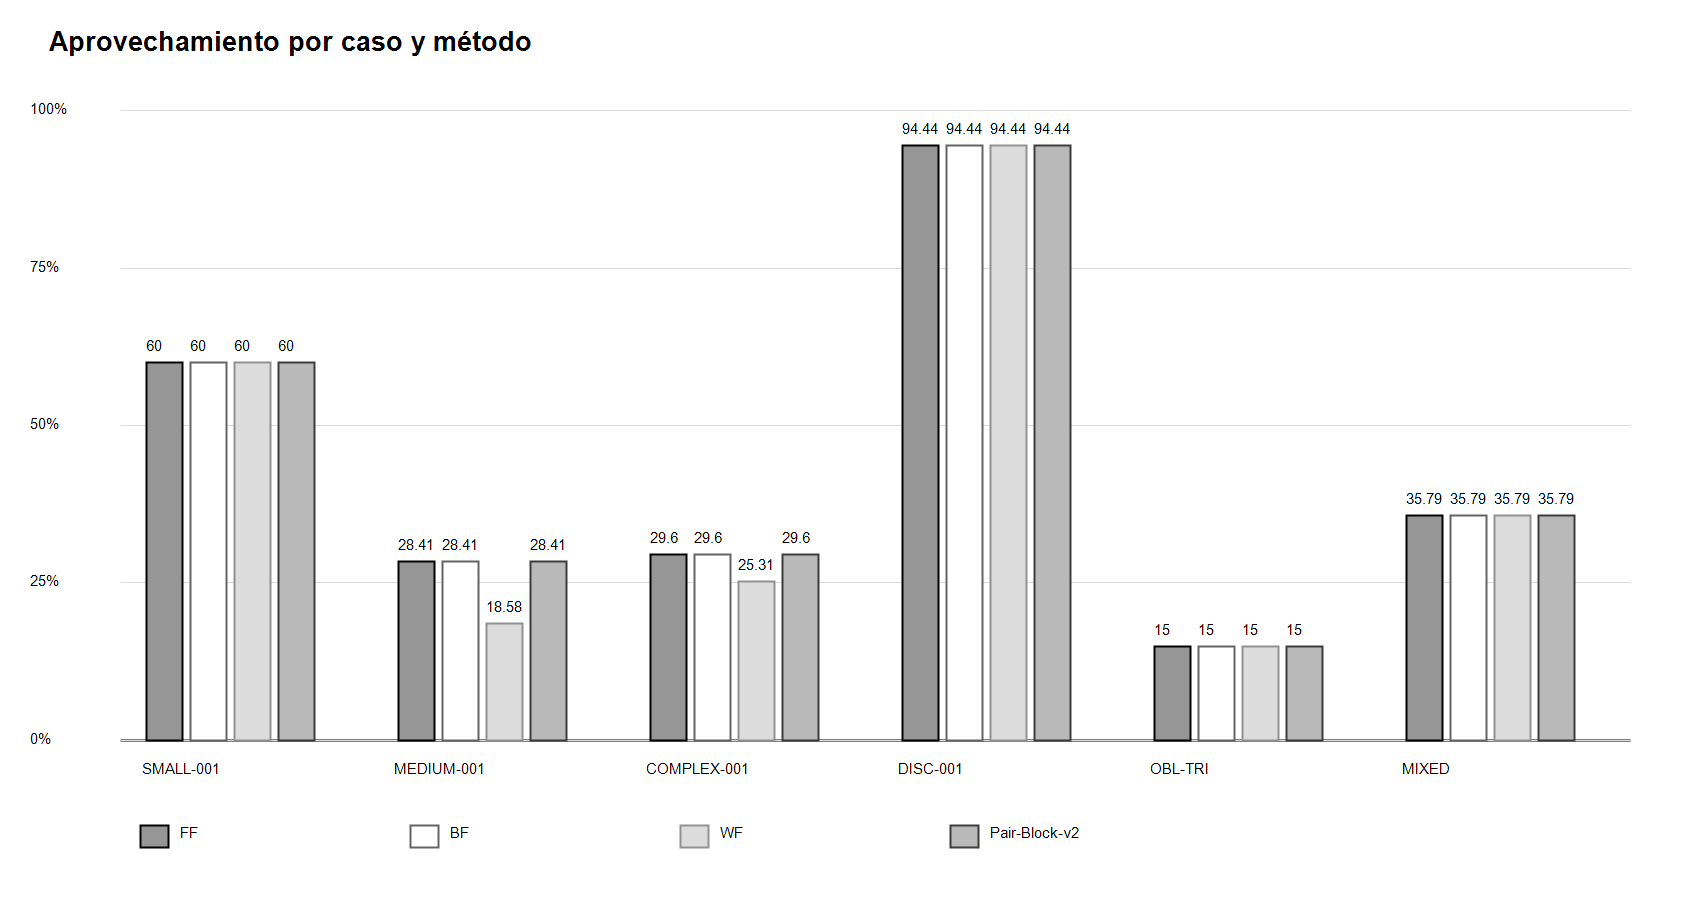

In [35]:
# Importamos el renderizador de Colab.
from IPython.display import Image, display
# Localizamos el gráfico en el repo.
chart_path = repo_root / "experiments/optimization/block_packing/figures/utilization-by-method.png"
# Mostramos el PNG de la corrida real.
display(Image(filename=str(chart_path)))

**Interpretación:** En TA-027 los métodos empatan en utilización; el diagnóstico oblicuo reduce merma, pero su tiempo es E.

## Fuentes por método

Ejecuta el paso experimental y muestra su salida guardada.

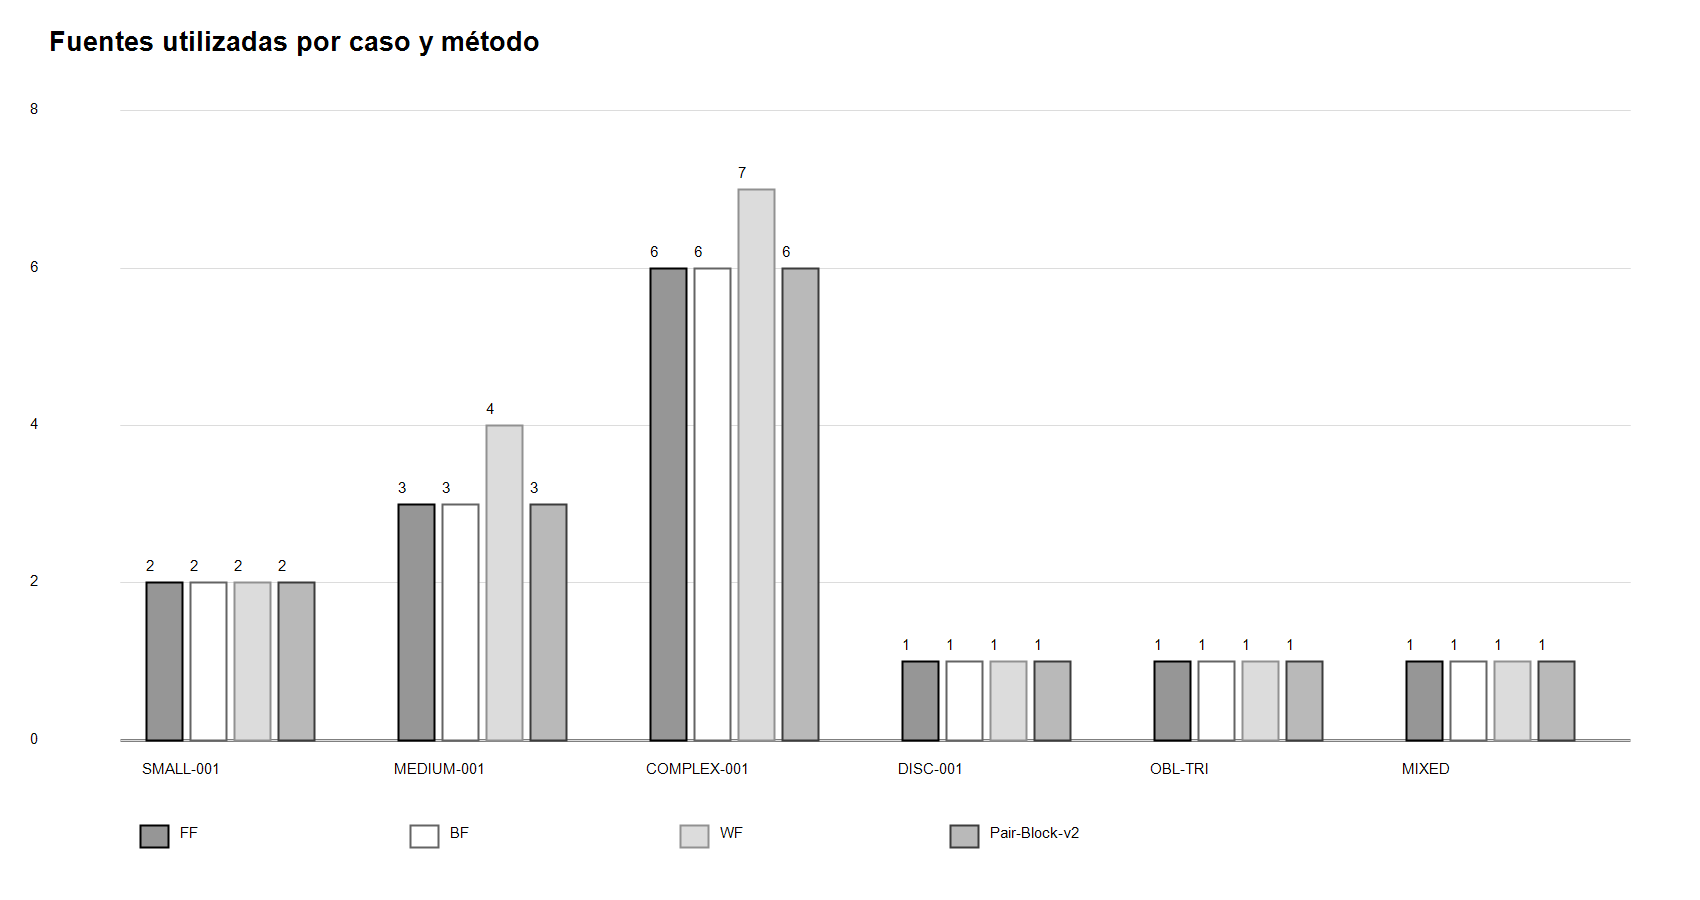

In [36]:
# Importamos el renderizador de Colab.
from IPython.display import Image, display
# Localizamos el gráfico en el repo.
chart_path = repo_root / "experiments/optimization/block_packing/figures/sources-by-method.png"
# Mostramos el PNG de la corrida real.
display(Image(filename=str(chart_path)))

**Interpretación:** Pair-Block v2 mantiene las fuentes de los baselines en SMALL/MEDIUM/COMPLEX.

## Tiempo por método

Ejecuta el paso experimental y muestra su salida guardada.

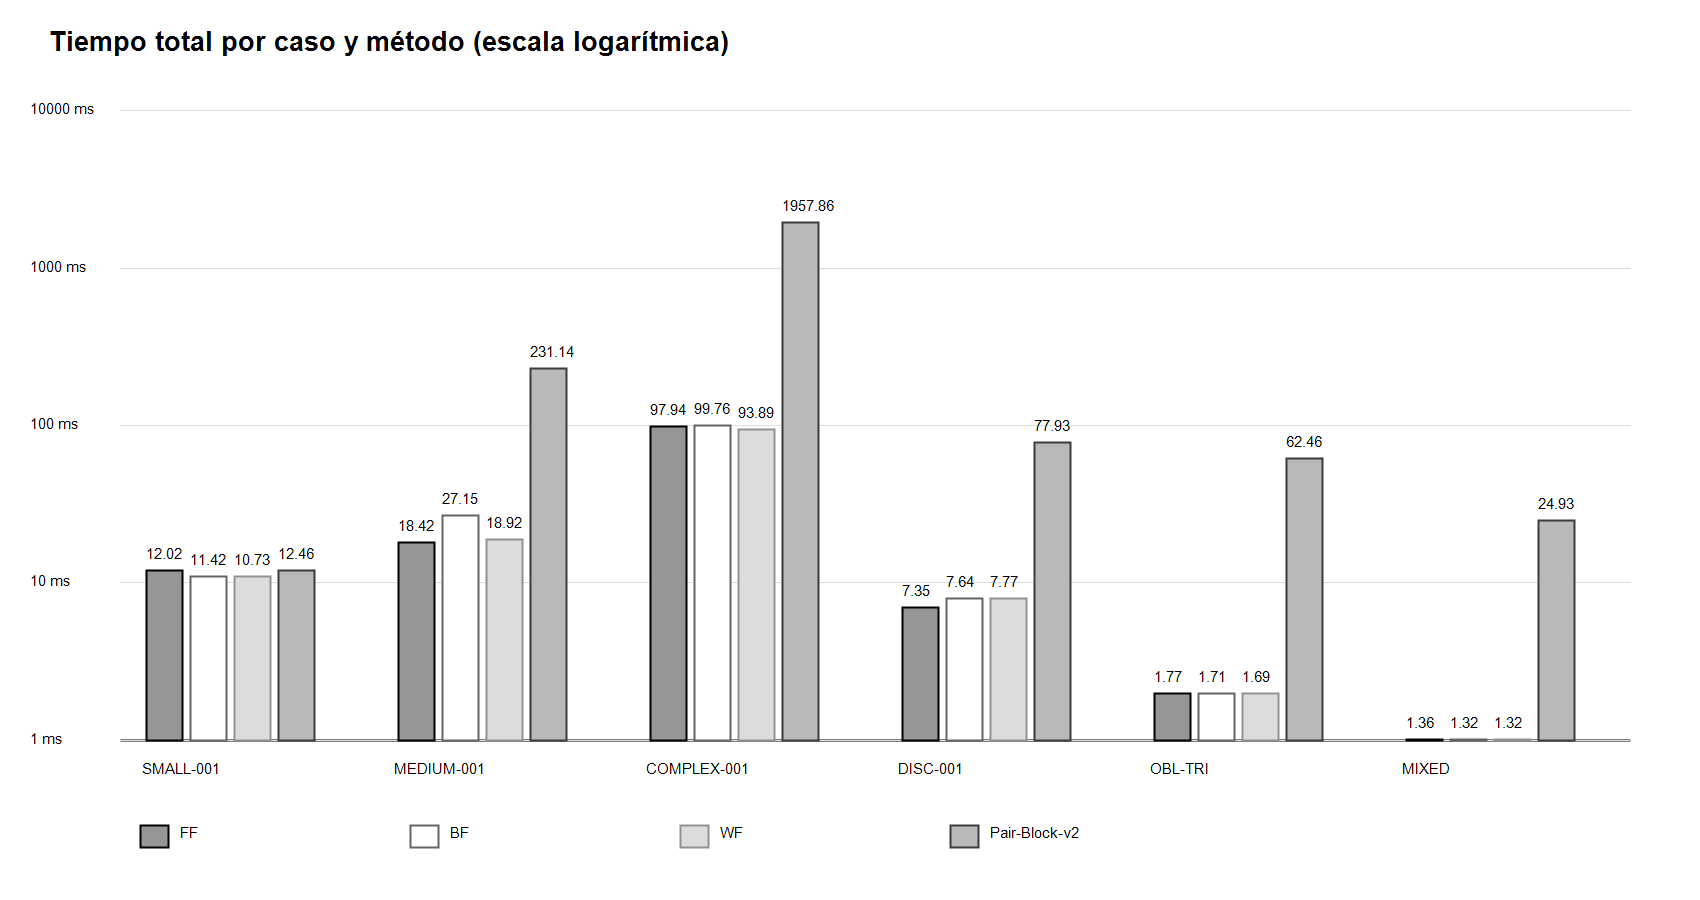

In [37]:
# Importamos el renderizador de Colab.
from IPython.display import Image, display
# Localizamos el gráfico en el repo.
chart_path = repo_root / "experiments/optimization/block_packing/figures/runtime-by-method.png"
# Mostramos el PNG de la corrida real.
display(Image(filename=str(chart_path)))

**Interpretación:** Los tiempos usan escala logarítmica; generación domina MEDIUM y COMPLEX.